# J1 · Pizzetti.jl in ten minutes

**Level:** beginner · **Prerequisites:** [J0](J0_install.ipynb) · **Run time:** ~1 min (mostly
compilation)

**Covers:** limb-darkening laws as sums of powers of $\mu$, `occult`, the `Occultor` (set up
once, evaluate many times), which method computes which sample, `evaluate!` for
allocation-free loops, transit light curves with exposure-time integration, and a first look
at derivatives and arbitrary precision (both treated in depth in [J2](J2_gradients.ipynb)
and [J3](J3_precision_and_rigour.ipynb)).

In [1]:
using Pizzetti, Plots
include("theme.jl")      # plotting style of these notebooks, and a `table` helper

## 1. Flux of an occulted star

`occult(z, p, law)` returns the relative flux of a star occulted by an opaque disk of radius
ratio $p$ at projected separations $z$, both in units of the stellar radius. Here the
power-2 law $I(\mu) = 1 - c\,(1 - \mu^\alpha)$ of Maxted (2018):

In [2]:
law = Power2(0.6, 0.6)
z = range(0, 1.15, length = 2000)
f = occult(z, 0.1, law)
f[1]                                   # flux at the centre of the disk

0.9884033280505852

Every supported law is a sum of powers of $\mu$, $I(\mu) = \sum_i c_i\,\mu^{\alpha_i}$, and the
flux is the same sum of the blocked integrals $P_{\alpha_i}$ (paper, Sect. 2).
`power_terms` shows the decomposition. `PowerSum` takes arbitrary exponents, `Polynomial`
the coefficients $u_n$ of $(1 - \mu)^n$ (Agol, Luger & Foreman-Mackey 2020).

In [3]:
laws = (Quadratic(0.4, 0.25), SquareRoot(0.3, 0.4), Nonlinear(0.5, 0.1, 0.2, -0.1), Power2(0.6, 0.6),
        Polynomial([0.3, 0.2, 0.1]), PowerSum([0.0, 0.7, 1.3], [0.5, 0.3, 0.2]))
fmt(v) = join(round.(v, digits = 3), ", ")
name(L) = replace(string(L), "Pizzetti." => "", "{Float64}" => "")
table(["law", "exponents αᵢ", "coefficients cᵢ"],
      [("`$(name(L))`", fmt(power_terms(L)[1]), fmt(power_terms(L)[2])) for L in laws]; align = "lll")

law,exponents αᵢ,coefficients cᵢ
"Quadratic(0.4, 0.25)","0.0, 1.0, 2.0","0.35, 0.9, -0.25"
"SquareRoot(0.3, 0.4)","0.0, 1.0, 0.5","0.3, 0.3, 0.4"
"Nonlinear(0.5, 0.1, 0.2, -0.1)","0.0, 0.5, 1.0, 1.5, 2.0","0.3, 0.5, 0.1, 0.2, -0.1"
"Power2(0.6, 0.6)","0.0, 0.6","0.4, 0.6"
"Polynomial([0.3, 0.2, 0.1])","0.0, 1.0, 2.0, 3.0","0.4, 1.0, -0.5, 0.1"
"PowerSum([0.0, 0.7, 1.3], [0.5, 0.3, 0.2])","0.0, 0.7, 1.3","0.5, 0.3, 0.2"


## 2. The Occultor, and which method computes which sample

An `Occultor` holds everything that depends only on $p$ and the law, so it is set up once per
light curve and then called like a function. While the planet is inside the disk and
$z \le z_c$, the flux is the **interior series** (paper, Sect. 5), whose truncation error is
*proven* to be below `series_tol` (default $10^{-9}$, Theorem 2). Beyond $z_c$, the quadratic
family uses the exact Mandel & Agol (2002) solution; the other laws (for $p < 0.3$) use the
fixed-node **trapezoid rule** for the limb integral (Sect. 6.4) or, for light curves with at
least `nlimb = 150` limb samples, **Chebyshev interpolants** built from it.

In [4]:
o = Occultor(0.1, law; nlimb = length(z))
m = method.(Ref(o), z)
table(["", ""], [("series cut z_c", round(o.zc, digits = 4)), ("second contact 1 - p", 0.9),
                      ("samples per method", join(["$k: $(count(==(k), m))" for k in unique(m)], ", "))])

,
series cut z_c,0.8203
second contact 1 - p,0.9
samples per method,"series: 1426, interpolate: 487, out: 87"


The flux deficit along $z$, coloured by the method that computes each sample: the series
covers the disk up to $z_c$, the interpolants the narrow band inside second contact and the
crossing of the limb.

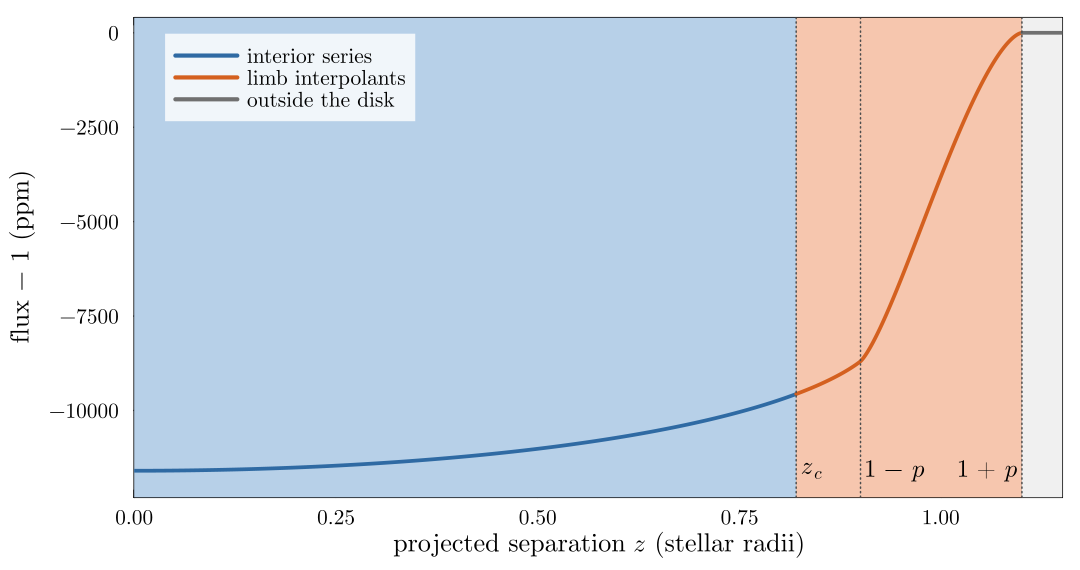

In [5]:
zc = o.zc
labels = Dict(:series => "interior series", :interpolate => "limb interpolants", :out => "outside the disk")
plt = plot(xlabel = L"projected separation $z$ (stellar radii)", ylabel = "flux − 1 (ppm)",
           legend = :topleft, xlims = (0, 1.15), ylims = (-12300, 400), size = (720, 380))
vspan!(plt, [0, zc], color = FILLS.series, lw = 0, label = "")
vspan!(plt, [zc, 1.1], color = FILLS.limb, lw = 0, label = "")
vspan!(plt, [1.1, 1.15], color = FILLS.out, lw = 0, label = "")
for k in unique(m)
    sel = m .== k
    plot!(plt, z[sel], 1e6 .* (f[sel] .- 1), color = METHOD_COLORS[k], lw = 2.5, label = labels[k])
end
for (x, lab) in ((zc, L"z_c"), (0.9, L"1-p"), (1.1, L"1+p"))
    vline!(plt, [x], color = :gray30, ls = :dot, lw = 1, label = "")
    annotate!(plt, x < 1.05 ? x + 0.007 : x - 0.007, -11600, text(lab, 11, x < 1.05 ? :left : :right))
end
plt

The limb method can also be chosen explicitly (`limb = :auto` is the default). On the samples
beyond $z_c$, against Green's-theorem quadrature: the trapezoid rule, its interpolants and the
contact expansions of Sect. 6.2 (`:fast`) agree to rounding; `:proven`, the certified pieces of
Sect. 6.3, carry a proven bound of `series_tol` instead, and stay below it.

In [6]:
zl = collect(range(zc + 1e-9, 1.1, length = 500))
ref = occult(zl, 0.1, law; limb = :quadrature, series_tol = 0)
table(["limb", "method used", "max abs ΔF against quadrature"],
      [("`:$lm`", "`:$(method(Occultor(0.1, law; limb = lm), 1.0))`",
        sci(maximum(abs.(occult(zl, 0.1, law; limb = lm) .- ref)))) for lm in (:trapezoid, :interpolate, :fast, :proven)])

limb,method used,max abs ΔF against quadrature
:trapezoid,:trapezoid,1.1e-16
:interpolate,:interpolate,1.1e-16
:fast,:contact,1.1e-16
:proven,:proven,5.6e-10


## 3. Evaluation into a buffer

In a loop (an MCMC step, an N-body integration), the `Occultor` and an output buffer are
reused. For the quadratic family `evaluate!` allocates nothing; for the other laws, only work
arrays for the limb samples. Timings with BenchmarkTools, for $10^5$ separations:

In [7]:
using BenchmarkTools
zs = collect(range(0, 1.2, length = 100_000))
out = similar(zs)
o2 = Occultor(0.1, law; nlimb = 20_000)
oq = Occultor(0.1, Quadratic(0.4, 0.25))
row(name, o, setup) = (name, @sprintf("%.3f ms", 1e3 * @belapsed(evaluate!($out, $o, $zs))),
                       @sprintf("%.1f µs", 1e6 * setup), @sprintf("%.0f KiB", (@allocated evaluate!(out, o, zs)) / 1024))
table(["law", "evaluate!, 10⁵ samples", "set-up", "allocated"],
      [row("power-2", o2, @belapsed(Occultor(0.1, $law; nlimb = 20_000))),
       row("quadratic", oq, @belapsed(Occultor(0.1, Quadratic(0.4, 0.25))))])

law,"evaluate!, 10⁵ samples",set-up,allocated
power-2,1.335 ms,34.3 µs,2270 KiB
quadratic,1.683 ms,4.7 µs,0 KiB


## 4. A transit light curve

`TransitParams` and `light_curve` compute the Keplerian orbit and the flux, with the
conventions of batman: `b` or `inc` (degrees) set the geometry, `ecc` and `w` (degrees) an
eccentric orbit, `exp_time` and `supersample` integrate over the exposure.

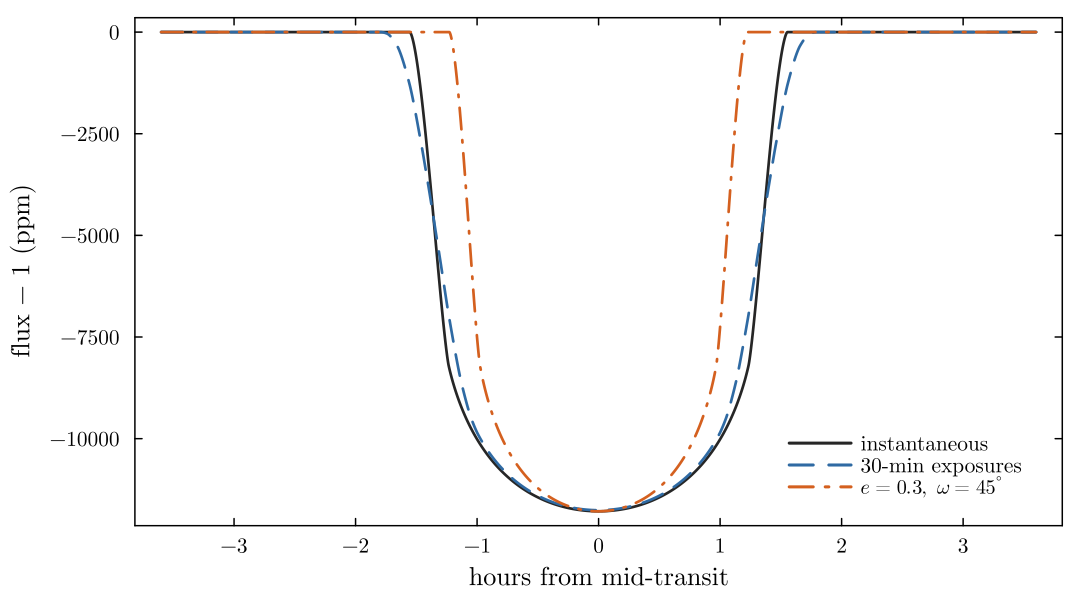

In [8]:
prm = TransitParams(per = 3.5, rp = 0.1, a = 9.0, b = 0.35, law = Quadratic(0.40, 0.25))
t = range(-0.15, 0.15, length = 3000)                                  # days
flux = light_curve(t, prm)
flux30 = light_curve(t, prm; exp_time = 30 / 1440, supersample = 7)   # 30-min exposures
fecc = light_curve(t, TransitParams(per = 3.5, rp = 0.1, a = 9.0, b = 0.35, ecc = 0.3, w = 45.0,
                                    law = Quadratic(0.40, 0.25)))
plt = plot(24t, 1e6 .* (flux .- 1), label = "instantaneous", color = COLORS.ink,
           xlabel = "hours from mid-transit", ylabel = "flux − 1 (ppm)", legend = :bottomright)
plot!(plt, 24t, 1e6 .* (flux30 .- 1), label = "30-min exposures", color = COLORS.series, ls = :dash)
plot!(plt, 24t, 1e6 .* (fecc .- 1), label = L"e = 0.3,\ \omega = 45^\circ", color = COLORS.limb, ls = :dashdot)
plt

## 5. Derivatives

With ForwardDiff loaded, dual numbers flow through everything. The flux derivatives with
respect to $z$ and $p$ are the exact hypergeometric expressions of the paper (Sect. 3.2), not
derivatives of a truncated series or of a quadrature rule. The gradient with respect to
$(z, p, c, \alpha)$ at $z = 0.95$, on the limb:

In [9]:
using ForwardDiff
g = ForwardDiff.gradient(v -> occult(v[1], v[2], Power2(v[3], v[4])), [0.95, 0.1, 0.6, 0.6])

4-element Vector{Float64}:
  0.05330839933551284
 -0.11145997876543198
  0.0027824347482397925
  0.0016878386693334297

`flux_gradient` returns the same derivatives without automatic differentiation:

In [10]:
F, dFdz, dFdp, dFdc = flux_gradient(0.95, 0.1, law)
[dFdz, dFdp] - g[1:2]

2-element Vector{Float64}:
  2.7755575615628914e-17
 -5.551115123125783e-17

More in [J2](J2_gradients.ipynb) (a gradient-based fit) and [J4](J4_photodynamics.ipynb)
(gradients through an N-body code).

## 6. Arbitrary precision

The code is generic in the number type. With `BigFloat`, a higher series order `M` and a
tighter tolerance give the flux to any number of digits:

In [11]:
fb = setprecision(BigFloat, 200) do
    occult(big"0.3", big"0.1", Power2(big"0.6", big"0.6"); series_tol = 1e-40, M = 61)
end

0.98859910878900066784659524170778666443999123508441641122343051

The Float64 value differs from it by a few units of rounding:

In [12]:
Float64(occult(0.3, 0.1, law) - fb)

-7.656687879613814e-17

More in [J3](J3_precision_and_rigour.ipynb).

## What you learned

- every law is a sum of powers of $\mu$, and `occult` and `Occultor` compute its flux;
- the interior series covers most of a transit with a proven error; the limb uses the exact
  quadratic solution, the trapezoid rule or its interpolants (or, on request, the contact
  expansions, their proven form, or quadrature);
- reuse an `Occultor` and `evaluate!` into a buffer in loops;
- `light_curve` follows the conventions of batman, derivatives and `BigFloat` work out of the box.

**Next:** [J2 · Gradients](J2_gradients.ipynb) for gradient-based fitting, or
[J3 · Precision and rigour](J3_precision_and_rigour.ipynb) for the proofs at work.